In [1]:
import geopandas as gpd

In [2]:
rivers_poly = gpd.read_file("jamuna_polygon.geojson")

In [3]:
rivers_line = gpd.read_file("jamuna.geojson")

In [4]:
rivers_poly.head()

,ripcode,rivname,shape_leng,k50,Basin_Code,st_area_sh,st_length_,geometry
0,01,None,0.0,0,None,1.066475e+06,71131.600314,"MULTIPOLYGON (((88.64993 26.49598, 88.65005 26..."


In [5]:
rivers_line.head()

,OBJECTID,rivname,sub_basin,ba_name,length_km,origin,major_trib,st_pt_lat,st_pt_long,st_loc_ste,...,en_loc_sb_,en_loc_vil,lat,long,UID_River,state_al,Confluence,remark,Shape_Leng,geometry
0,101,Jamuna,Brahmaputra Lower,Brahmaputra,40.509591,None,None,26.511132,88.645706,West Bengal,...,Jalpaiguri,Berubari,26.410491,88.707811,929,West Bengal,Panga,Jamuna,40509.591017,"LINESTRING (88.64571 26.51113, 88.64585 26.510..."


In [6]:
rivers_poly.shape

(1, 8)

In [7]:
rivers_line.shape

(1, 27)

In [8]:
rivers_poly.columns

Index(['ripcode', 'rivname', 'shape_leng', 'k50', 'Basin_Code', 'st_area_sh',
       'st_length_', 'geometry'],
      dtype='str')

In [9]:
rivers_line.columns

Index(['OBJECTID', 'rivname', 'sub_basin', 'ba_name', 'length_km', 'origin',
       'major_trib', 'st_pt_lat', 'st_pt_long', 'st_loc_ste', 'st_loc_dst',
       'st_loc_sb_', 'st_loc_vil', 'en_pt_lat', 'en_pt_long', 'en_loc_ste',
       'en_loc_dst', 'en_loc_sb_', 'en_loc_vil', 'lat', 'long', 'UID_River',
       'state_al', 'Confluence', 'remark', 'Shape_Leng', 'geometry'],
      dtype='str')

In [10]:
rivers_poly.geometry.geom_type

0    MultiPolygon
dtype: str

In [11]:
rivers_line.geometry.geom_type

0    LineString
dtype: str

In [12]:
rivers_poly.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [13]:
rivers_line.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

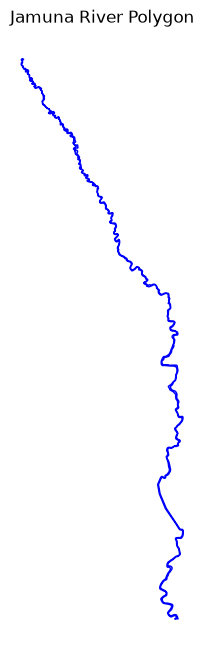

In [13]:
import matplotlib.pyplot as plt

rivers_poly.plot(
    figsize=(10, 8),
    color="lightblue",
    edgecolor="blue"
)

plt.title("Jamuna River Polygon")
plt.axis("off")
plt.show()

In [14]:
rivers_poly["Area_m2"] = rivers_poly.geometry.area
rivers_poly[["rivname", "Area_m2"]]


C:\Users\user\AppData\Local\Temp\ipykernel_4576\3974027218.py:1: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  rivers_poly["Area_m2"] = rivers_poly.geometry.area


,rivname,Area_m2
0,None,0.000104


In [15]:
rivers_poly["Area_km2"] = (
    rivers_poly["Area_m2"] / 1_000_000
)

In [16]:
rivers_poly[
    ["rivname", "Area_m2", "Area_km2"]
]

,rivname,Area_m2,Area_km2
0,None,0.000104,1.038369e-10


In [17]:
rivers_poly[
    ["rivname", "st_area_sh", "Area_m2"]
]


,rivname,st_area_sh,Area_m2
0,None,1.066475e+06,0.000104


In [18]:
rivers_poly["Boundary_m"] = rivers_poly.geometry.length
rivers_poly["Boundary_km"] = (
    rivers_poly["Boundary_m"] / 1000
)
rivers_poly[
    ["rivname", "Boundary_m", "Boundary_km"]
]

C:\Users\user\AppData\Local\Temp\ipykernel_4576\2978661556.py:1: UserWarning: Geometry is in a geographic CRS. Results from 'length' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  rivers_poly["Boundary_m"] = rivers_poly.geometry.length


,rivname,Boundary_m,Boundary_km
0,None,0.717449,0.000717


In [19]:
rivers_line["Length_m"] = rivers_line.geometry.length

rivers_line["Length_km_calculated"] = (
    rivers_line["Length_m"] / 1000
)

rivers_line[
    ["rivname", "Length_m", "Length_km_calculated"]
]

C:\Users\user\AppData\Local\Temp\ipykernel_4576\1581179110.py:1: UserWarning: Geometry is in a geographic CRS. Results from 'length' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  rivers_line["Length_m"] = rivers_line.geometry.length


,rivname,Length_m,Length_km_calculated
0,Jamuna,0.390806,0.000391


In [20]:
start_point = rivers_line.geometry.iloc[0].coords[0]
end_point = rivers_line.geometry.iloc[0].coords[-1]

print("Start point:", start_point)
print("End point:", end_point)

Start point: (88.64570596625128, 26.511132338382097)
End point: (88.71643496152953, 26.280886905191014)


In [21]:
straight_distance_m = (
    rivers_line.geometry.iloc[0].coords[0]
)

In [22]:
from shapely.geometry import Point

start = Point(start_point)
end = Point(end_point)

In [23]:
from shapely.geometry import Point

start = Point(rivers_line.geometry.iloc[0].coords[0])
end = Point(rivers_line.geometry.iloc[0].coords[-1])

straight_distance_m = start.distance(end)
straight_distance_km = straight_distance_m / 1000

straight_distance_km

0.00024086417392053022

In [24]:
actual_length_km = rivers_line.geometry.length.iloc[0] / 1000

sinuosity = actual_length_km / straight_distance_km

sinuosity

C:\Users\user\AppData\Local\Temp\ipykernel_4576\3360022309.py:1: UserWarning: Geometry is in a geographic CRS. Results from 'length' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  actual_length_km = rivers_line.geometry.length.iloc[0] / 1000


np.float64(1.62251705972252)

In [25]:
rivers_poly["Centroid"] = rivers_poly.geometry.centroid

C:\Users\user\AppData\Local\Temp\ipykernel_4576\3139295007.py:1: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  rivers_poly["Centroid"] = rivers_poly.geometry.centroid


In [26]:
centroid = rivers_poly.geometry.centroid.iloc[0]

centroid.x, centroid.y

C:\Users\user\AppData\Local\Temp\ipykernel_4576\2238633907.py:1: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  centroid = rivers_poly.geometry.centroid.iloc[0]


(88.70129236711269, 26.383560770871078)

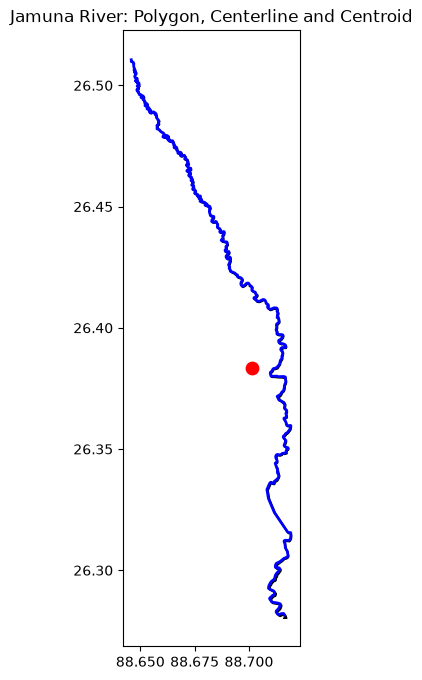

In [27]:
fig, ax = plt.subplots(figsize=(10, 8))

rivers_poly.plot(
    ax=ax,
    color="lightblue",
    edgecolor="black"
)

rivers_line.plot(
    ax=ax,
    color="blue",
    linewidth=2
)

gpd.GeoSeries(
    [centroid],
    crs=rivers_poly.crs
).plot(
    ax=ax,
    color="red",
    markersize=80
)

plt.title("Jamuna River: Polygon, Centerline and Centroid")
plt.show()

In [28]:
rivers_line[
    [
        "rivname",
        "sub_basin",
        "ba_name",
        "length_km",
        "state_al",
        "Confluence"
    ]
]

,rivname,sub_basin,ba_name,length_km,state_al,Confluence
0,Jamuna,Brahmaputra Lower,Brahmaputra,40.509591,West Bengal,Panga


In [29]:
river_length_km = (
    rivers_line.geometry.length.iloc[0] / 1000
)

river_area_km2 = (
    rivers_poly.geometry.area.iloc[0] / 1_000_000
)

boundary_km = (
    rivers_poly.geometry.length.iloc[0] / 1000
)

C:\Users\user\AppData\Local\Temp\ipykernel_4576\670602984.py:2: UserWarning: Geometry is in a geographic CRS. Results from 'length' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  rivers_line.geometry.length.iloc[0] / 1000
C:\Users\user\AppData\Local\Temp\ipykernel_4576\670602984.py:6: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  rivers_poly.geometry.area.iloc[0] / 1_000_000
C:\Users\user\AppData\Local\Temp\ipykernel_4576\670602984.py:10: UserWarning: Geometry is in a geographic CRS. Results from 'length' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  rivers_poly.geometry.length.iloc[0] / 1000


In [30]:
print("========== JAMUNA RIVER GEOMETRY ANALYSIS ==========")

print(f"Mapped line length     : {river_length_km:.2f} km")
print(f"Straight-line distance : {straight_distance_km:.2f} km")
print(f"Sinuosity              : {sinuosity:.2f}")
print(f"Polygon area           : {river_area_km2:.2f} km²")
print(f"Polygon boundary       : {boundary_km:.2f} km")

========== JAMUNA RIVER GEOMETRY ANALYSIS ==========
Mapped line length     : 0.00 km
Straight-line distance : 0.00 km
Sinuosity              : 1.62
Polygon area           : 0.00 km²
Polygon boundary       : 0.00 km


In [31]:
print("========== JAMUNA RIVER GEOMETRY ANALYSIS ==========")

print(f"Mapped line length     : {river_length_km:.2f} km")
print(f"Straight-line distance : {straight_distance_km:.2f} km")
print(f"Sinuosity              : {sinuosity:.2f}")
print(f"Polygon area           : {river_area_km2:.2f} km²")
print(f"Polygon boundary       : {boundary_km:.2f} km")

========== JAMUNA RIVER GEOMETRY ANALYSIS ==========
Mapped line length     : 0.00 km
Straight-line distance : 0.00 km
Sinuosity              : 1.62
Polygon area           : 0.00 km²
Polygon boundary       : 0.00 km
